# LAB 3 - Bài 3: Phân lớp MNIST bằng Neural Network (10-fold cross validation)
Hồng Kim Dung - 6451071009

## Câu a - Đọc bộ dữ liệu MNIST

In [1]:
print("Hồng Kim Dung - 6451071009")
from tensorflow.keras.datasets import mnist

(train_images, train_labels), (test_images, test_labels) = mnist.load_data()
print("Đã đọc xong bộ dữ liệu MNIST")

Hồng Kim Dung - 6451071009
11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Đã đọc xong bộ dữ liệu MNIST


## Câu b - Kích thước tập train, test

In [2]:
print("Hồng Kim Dung - 6451071009")
print("train_images:", train_images.shape, "| train_labels:", train_labels.shape)
print("test_images :", test_images.shape, "| test_labels :", test_labels.shape)

Hồng Kim Dung - 6451071009
train_images: (60000, 28, 28) | train_labels: (60000,)
test_images : (10000, 28, 28) | test_labels : (10000,)


## Câu c - Chuẩn hóa pixel về [0,1]

In [3]:
print("Hồng Kim Dung - 6451071009")
train_images = train_images / 255.0
test_images = test_images / 255.0
print("Min:", train_images.min(), "| Max:", train_images.max())

Hồng Kim Dung - 6451071009
Min: 0.0 | Max: 1.0


## Câu d - Hàm create_model

In [4]:
print("Hồng Kim Dung - 6451071009")
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Flatten, Dense, Dropout, Input

def create_model():
    model = Sequential([
        Input(shape=(28, 28)),
        Flatten(),
        Dense(128, activation="relu"),
        Dropout(0.2),
        Dense(10, activation="softmax"),
    ])
    model.compile(optimizer="adam",
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])
    return model

create_model().summary()

Hồng Kim Dung - 6451071009


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

## Câu e - Huấn luyện bằng 10-fold cross validation (chạy khoảng 5-10 phút)

In [5]:
print("Hồng Kim Dung - 6451071009")
import numpy as np
from sklearn.model_selection import KFold

kfold = KFold(n_splits=10, shuffle=True, random_state=42)

models = []
accuracy_per_fold = []
loss_per_fold = []

for fold, (train_index, val_index) in enumerate(kfold.split(train_images), start=1):
    model = create_model()
    X_train_fold, X_val_fold = train_images[train_index], train_images[val_index]
    y_train_fold, y_val_fold = train_labels[train_index], train_labels[val_index]

    model.fit(X_train_fold, y_train_fold,
              validation_data=(X_val_fold, y_val_fold),
              epochs=5, batch_size=32, verbose=0)

    models.append(model)
    loss, acc = model.evaluate(X_val_fold, y_val_fold, verbose=0)
    accuracy_per_fold.append(acc)
    loss_per_fold.append(loss)
    print(f"Fold {fold:2d}: loss = {loss:.4f} - accuracy = {acc:.4f}")

Hồng Kim Dung - 6451071009
Fold  1: loss = 0.0756 - accuracy = 0.9772
Fold  2: loss = 0.0961 - accuracy = 0.9705
Fold  3: loss = 0.0862 - accuracy = 0.9745
Fold  4: loss = 0.0766 - accuracy = 0.9780
Fold  5: loss = 0.1001 - accuracy = 0.9730
Fold  6: loss = 0.0840 - accuracy = 0.9747
Fold  7: loss = 0.0953 - accuracy = 0.9712
Fold  8: loss = 0.0885 - accuracy = 0.9737
Fold  9: loss = 0.0898 - accuracy = 0.9717
Fold 10: loss = 0.0819 - accuracy = 0.9752


## Câu f - Mean / Std của Accuracy và Loss

In [6]:
print("Hồng Kim Dung - 6451071009")
print("Mean Accuracy :", np.mean(accuracy_per_fold))
print("Std Accuracy  :", np.std(accuracy_per_fold))
print("Mean Loss     :", np.mean(loss_per_fold))
print("Std Loss      :", np.std(loss_per_fold))

Hồng Kim Dung - 6451071009
Mean Accuracy : 0.9739499986171722
Std Accuracy  : 0.0023428913049295505
Mean Loss     : 0.08738453835248947
Std Loss      : 0.007777188332631071


## Câu g - Biểu đồ accuracy, loss theo từng fold

Hồng Kim Dung - 6451071009


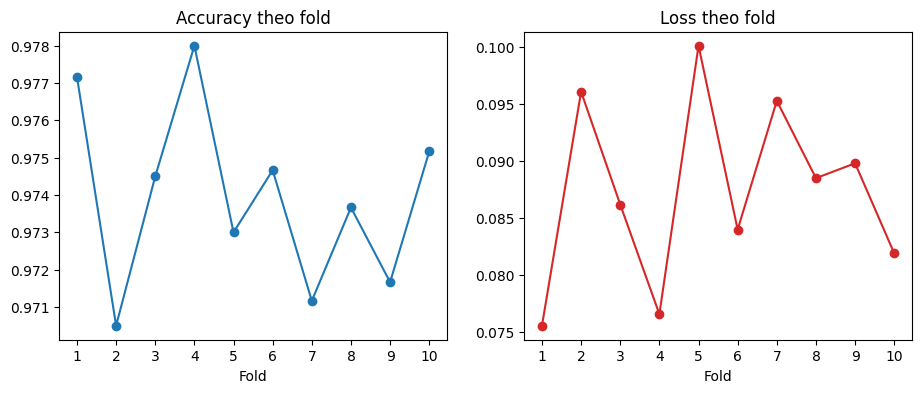

In [7]:
print("Hồng Kim Dung - 6451071009")
import matplotlib.pyplot as plt

folds = range(1, 11)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(folds, accuracy_per_fold, marker="o", color="tab:blue")
ax[0].set_title("Accuracy theo fold"); ax[0].set_xlabel("Fold"); ax[0].set_xticks(list(folds))

ax[1].plot(folds, loss_per_fold, marker="o", color="tab:red")
ax[1].set_title("Loss theo fold"); ax[1].set_xlabel("Fold"); ax[1].set_xticks(list(folds))
plt.show()

## Câu h - Chọn mô hình tốt nhất và dự đoán tập test

In [8]:
print("Hồng Kim Dung - 6451071009")
best_index = np.argmax(accuracy_per_fold)
best_model = models[best_index]
print("Fold tốt nhất:", best_index + 1, "- accuracy =", accuracy_per_fold[best_index])

y_prob = best_model.predict(test_images)
y_pred = np.argmax(y_prob, axis=1)

Hồng Kim Dung - 6451071009
Fold tốt nhất: 4 - accuracy = 0.9779999852180481
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step


## Câu i - Accuracy trên tập test

In [9]:
print("Hồng Kim Dung - 6451071009")
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("Accuracy:", accuracy_score(test_labels, y_pred))

Hồng Kim Dung - 6451071009
Accuracy: 0.9759


## Câu j - Precision, Recall, F1-score

In [10]:
print("Hồng Kim Dung - 6451071009")
print(classification_report(test_labels, y_pred, digits=4))

Hồng Kim Dung - 6451071009
              precision    recall  f1-score   support

           0     0.9868    0.9898    0.9883       980
           1     0.9860    0.9894    0.9877      1135
           2     0.9768    0.9777    0.9772      1032
           3     0.9512    0.9851    0.9679      1010
           4     0.9844    0.9644    0.9743       982
           5     0.9830    0.9697    0.9763       892
           6     0.9842    0.9781    0.9812       958
           7     0.9672    0.9767    0.9719      1028
           8     0.9739    0.9589    0.9664       974
           9     0.9673    0.9663    0.9668      1009

    accuracy                         0.9759     10000
   macro avg     0.9761    0.9756    0.9758     10000
weighted avg     0.9760    0.9759    0.9759     10000



## Câu k - Confusion matrix (heat map)

Hồng Kim Dung - 6451071009


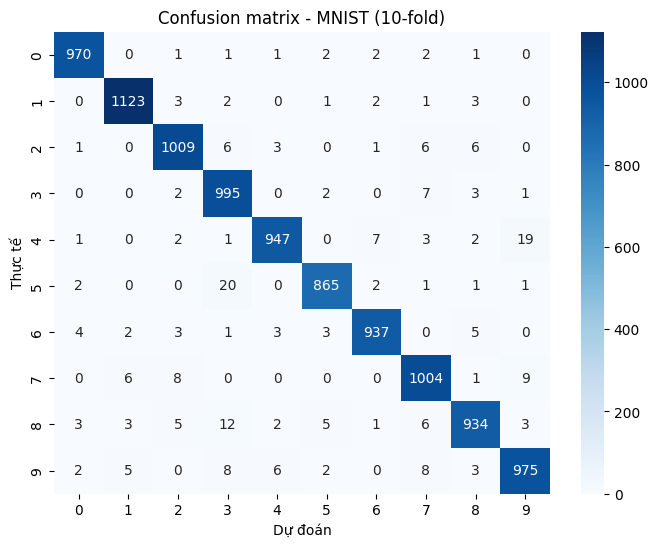

In [11]:
print("Hồng Kim Dung - 6451071009")
import seaborn as sns

cm = confusion_matrix(test_labels, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Dự đoán"); plt.ylabel("Thực tế"); plt.title("Confusion matrix - MNIST (10-fold)")
plt.show()

## Câu l - Phân lớp 5 ảnh đầu tiên của tập test

Hồng Kim Dung - 6451071009
Ảnh 0: dự đoán = 7, thực tế = 7
Ảnh 1: dự đoán = 2, thực tế = 2
Ảnh 2: dự đoán = 1, thực tế = 1
Ảnh 3: dự đoán = 0, thực tế = 0
Ảnh 4: dự đoán = 4, thực tế = 4


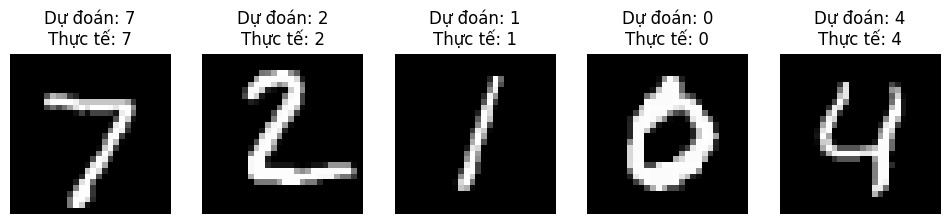

In [12]:
print("Hồng Kim Dung - 6451071009")
plt.figure(figsize=(12, 3))
for i in range(5):
    img = np.expand_dims(test_images[i], axis=0)       # (1, 28, 28)
    pred = np.argmax(best_model.predict(img, verbose=0), axis=1)[0]
    plt.subplot(1, 5, i + 1)
    plt.imshow(test_images[i], cmap="gray")
    plt.title(f"Dự đoán: {pred}\nThực tế: {test_labels[i]}")
    plt.axis("off")
    print(f"Ảnh {i}: dự đoán = {pred}, thực tế = {test_labels[i]}")
plt.show()